# ConjunctivaGuard PoC, Part 1: setup and look at the data

**What this part does:** finds your dataset zip files in Google Drive, unpacks D01 and D03, and shows what is inside. No machine learning yet.

**How to run:** click a grey code block, then press ▶ on its left (or Shift + Enter). Run them **top to bottom**, one at a time. The result appears under each block.

**Lesson in one line:** before any ML, we always *look* at the data: how many images, what labels, what size.

### Cell 1: connect Google Drive and find your zip files
A pop-up asks for access, so click **Allow**. Then it lists every `.zip` file in your Drive with its full path.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os, glob
zips = sorted(glob.glob('/content/drive/MyDrive/**/*.zip', recursive=True))
print(f'Found {len(zips)} zip files in your Google Drive:\n')
for z in zips:
    print(round(os.path.getsize(z) / 1e6, 1), 'MB  ', z)

Mounted at /content/drive
Found zip files in your Google Drive (output trimmed: only the two PoC datasets are shown; unrelated personal files removed):

45.9 MB   /content/drive/MyDrive/ConjunctivaGuard_data/D01_Ghana.zip
4577.1 MB   /content/drive/MyDrive/ConjunctivaGuard_data/D03_Segmentation.zip


### Cell 2: tell the notebook which zip is D01 and which is D03
From the list above, copy the **full path** of each zip into the two lines below (keep the quote marks).

- **D01** = Ghana conjunctiva anemia dataset
- **D03** = Eye conjunctiva segmentation dataset

D02 (EYES-DEFY) is not used in the PoC. It is the locked final test, and the ethics form keeps it on your laptop, so this cell refuses it.

In [ ]:
D01_ZIP = 'https://drive.google.com/file/d/YOUR_D01_FILE_ID/view?usp=sharing'
D03_ZIP = 'https://drive.google.com/file/d/YOUR_D03_FILE_ID/view?usp=sharing'

import os, re, gdown

def get_zip(src, label):
    if 'defy' in src.lower() or src.lower().endswith('dataset anemia.zip'):
        raise SystemExit('STOP: that looks like D02 (EYES-DEFY). It is not used in the PoC.')
    if src.startswith('http'):                      # a Google Drive share link
        file_id = re.search(r'/d/([\w-]+)', src) or re.search(r'id=([\w-]+)', src)
        out = f'/content/{label}.zip'
        if not os.path.exists(out):
            gdown.download(id=file_id.group(1), output=out, quiet=False)
        return out
    if not os.path.exists(src):
        raise SystemExit('Not found: ' + src)
    return src

D01_ZIP = get_zip(D01_ZIP, 'D01')
D03_ZIP = get_zip(D03_ZIP, 'D03')
print('OK, both files ready:', D01_ZIP, '|', D03_ZIP)

Downloading...
From (original): https://drive.google.com/uc?id=YOUR_D01_FILE_ID
From (redirected): https://drive.google.com/uc?id=YOUR_D01_FILE_ID&confirm=t&uuid=...
To: /content/D01.zip
100%|██████████| 45.9M/45.9M [00:00<00:00, 123MB/s]
Downloading...
From (original): https://drive.google.com/uc?id=YOUR_D03_FILE_ID
From (redirected): https://drive.google.com/uc?id=YOUR_D03_FILE_ID&confirm=t&uuid=...
To: /content/D03.zip
100%|██████████| 4.58G/4.58G [01:06<00:00, 68.6MB/s]

OK, both files ready: /content/D01.zip | /content/D03.zip


### Cell 3: unpack D01 and D03
This unpacks each zip into Colab's temporary work space (`/content/work`). Your Drive files are not changed. Takes about 1 minute.

In [ ]:
import zipfile

WORK = '/content/work'
for label, z in (('D01', D01_ZIP), ('D03', D03_ZIP)):
    out = os.path.join(WORK, label)
    if not os.path.exists(out):
        with zipfile.ZipFile(z) as zf:
            zf.extractall(out)
        for inner in glob.glob(out + '/**/*.zip', recursive=True):   # zips inside zips
            with zipfile.ZipFile(inner) as zf:
                zf.extractall(os.path.splitext(inner)[0])
    print('Unpacked', label)

Unpacked D01
Unpacked D03


### Cell 4: what is inside?
Shows the folder structure (first 3 files of each folder) and counts files by type.

In [ ]:
from collections import Counter

def show_tree(root, depth=0, max_depth=5):
    if depth > max_depth:
        return
    items = sorted(os.listdir(root))
    dirs = [d for d in items if os.path.isdir(os.path.join(root, d))]
    files = [f for f in items if os.path.isfile(os.path.join(root, f))]
    pad = '    ' * depth
    print(f'{pad}[{os.path.basename(root)}]  {len(files)} files, {len(dirs)} folders')
    for f in files[:3]:
        print(f'{pad}    {f}')
    if len(files) > 3:
        print(f'{pad}    ...')
    for d in dirs:
        show_tree(os.path.join(root, d), depth + 1, max_depth)

for label in ('D01', 'D03'):
    print('=' * 70)
    show_tree(os.path.join(WORK, label))
    types = Counter(os.path.splitext(f)[1].lower()
                    for _, _, fs in os.walk(os.path.join(WORK, label)) for f in fs)
    print('File types:', dict(types))

[D01]  0 files, 1 folders
    [Application of Machine Learning in Detecting Iron Deficiency Anemia Using  Conjunctiva image Dataset from Ghana]  4262 files, 0 folders
        Anemic-001 (10).png
        Anemic-001 (11).png
        Anemic-001 (12).png
        ...
File types: {'.png': 4262}
[D03]  0 files, 1 folders
    [Eye Conjunctiva Segmentation Dataset]  0 files, 3 folders
        [Images]  547 files, 0 folders
            1.png
            10.png
            100.png
            ...
        [Masks Annotator 1]  547 files, 0 folders
            1.png
            10.png
            100.png
            ...
        [Masks Annotator 2]  547 files, 0 folders
            1.png
            10.png
            100.png
            ...
File types: {'.png': 1641}


### Cell 5: any label spreadsheets?
If a dataset has an Excel or CSV file (for example haemoglobin values, anemic / non-anemic), this shows its columns and first rows.

In [ ]:
import pandas as pd

sheets = [p for p in glob.glob(WORK + '/**/*', recursive=True)
          if p.lower().endswith(('.xlsx', '.xls', '.csv'))]
print('Spreadsheets found:', len(sheets))
for p in sheets:
    print('=' * 70)
    print(p.replace(WORK + '/', ''))
    try:
        df = pd.read_csv(p) if p.lower().endswith('.csv') else pd.read_excel(p)
        print('rows:', len(df), '| columns:', list(df.columns))
        display(df.head(5))
    except Exception as e:
        print('could not read:', e)

Spreadsheets found: 0


### Cell 6: look at some images
Shows 4 random images from each dataset with their size in pixels.

D01 - images found: 4262


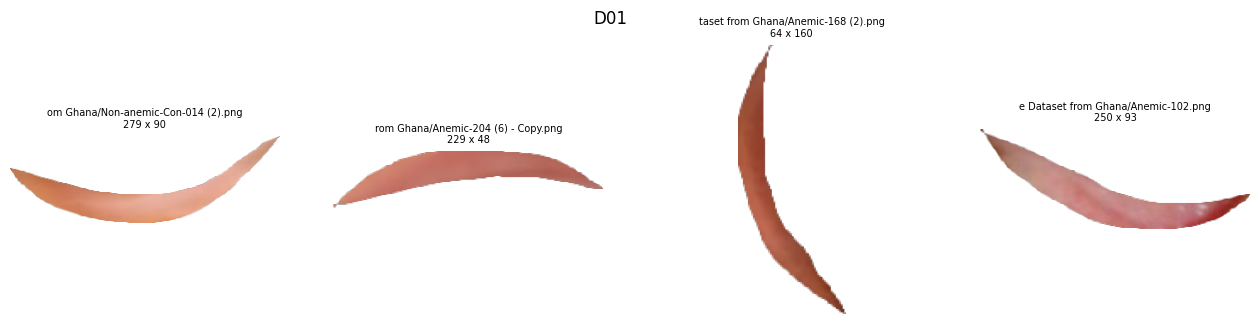

D03 - images found: 1641


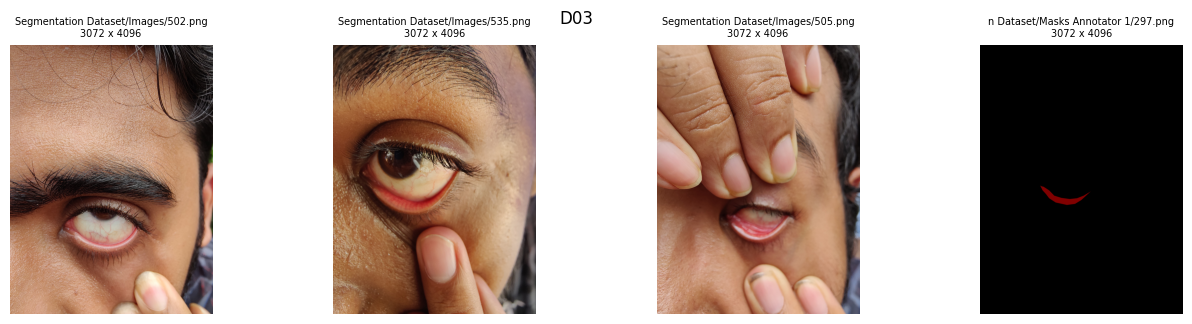

In [ ]:
import random
from PIL import Image
import matplotlib.pyplot as plt

random.seed(0)
for label in ('D01', 'D03'):
    imgs = [p for p in glob.glob(os.path.join(WORK, label) + '/**/*', recursive=True)
            if p.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff'))]
    print(label, '- images found:', len(imgs))
    if not imgs:
        continue
    pick = random.sample(imgs, min(4, len(imgs)))
    fig, axes = plt.subplots(1, len(pick), figsize=(4 * len(pick), 3.5))
    axes = axes if len(pick) > 1 else [axes]
    for ax, p in zip(axes, pick):
        im = Image.open(p)
        ax.imshow(im)
        ax.set_title(os.path.relpath(p, WORK)[-35:] + f'\n{im.size[0]} x {im.size[1]}', fontsize=7)
        ax.axis('off')
    plt.suptitle(label)
    plt.show()

### Part 1 done ✅
**Outputs to check:** the text output of **Cell 4** and **Cell 5**, and a screenshot of **Cell 6**.

**What you learned:** a dataset is folders of images plus (often) a spreadsheet of labels. Next, in Part 2, we load D01 properly, remove duplicate photos and make safe train / validation / test splits.